# FER2013 — MobileNetV3-Small với hiệu chỉnh theo cặp biểu cảm

Notebook độc lập cho thí nghiệm: **backbone dùng chung → global classifier +
attention theo cặp → hiệu chỉnh logits có gate**. Cấu hình mặc định có
**933.805 tham số** với 3 cặp; global-only có **931.047 tham số**.

MobileNetV3-Small pretrained ImageNet là thành phần có sẵn. Cách dùng attention
để hiệu chỉnh từng cặp là giả thuyết thử nghiệm; chưa có accuracy và chưa xác
nhận tính mới học thuật. Không gán trước vai trò mắt/miệng cho attention map.

**Quy trình:** train global-only pilot 5 epoch → chọn cặp từ validation → cố
định cặp → copy backbone/global classifier từ best pilot → train chính 45 epoch.
Tổng ngân sách 50 epoch ở mặc định. Test được giữ riêng đến bước cuối.

**Kaggle:** gắn dataset `msambare/fer2013`, bật GPU; bật Internet để tải weights
lần đầu hoặc gắn file MobileNetV3-Small ImageNet và đặt `backbone_weights_path`.
Chạy từ trên xuống. Chỉ train một preset mỗi lần, không cần clone repo hoặc
cài lại torch. Model nhỏ dùng một GPU mặc định; có tùy chọn hai GPU.

In [1]:
import json
import hashlib
import itertools
import math
import os
import random
import sys
from time import perf_counter
from concurrent.futures import ThreadPoolExecutor
from contextlib import closing, nullcontext
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, models, transforms
from tqdm.auto import tqdm

CLASS_NAMES = ('angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise')
NORMALIZE_MEAN = (0.485, 0.456, 0.406)
NORMALIZE_STD = (0.229, 0.224, 0.225)
print(f'Python {sys.version.split()[0]} | torch {torch.__version__} | torchvision {torchvision.__version__}')

Python 3.13.16 | torch 2.11.0+cu130 | torchvision 0.26.0+cu130


## 1. Preset và cấu hình

| Preset | Nhánh hiệu chỉnh | Gate | Loss phân loại |
|---|---|---|---|
| `global_ce` | Không | — | Cross-Entropy |
| `pair_ce` | Cặp chọn theo validation | Có | Cross-Entropy |
| `global_balanced` | Không | — | CE có trọng số effective number |
| `pair_balanced` (mặc định) | Cặp chọn theo validation | Có | CE có trọng số effective number |
| `pair_no_gate` | Cặp chọn theo validation | Tắt | CE có trọng số effective number |
| `pair_random` | Cặp ngẫu nhiên, không dùng test | Có | CE có trọng số effective number |

Pilot luôn dùng global-only, CE thông thường, seed `mining_seed=42`, không
MixUp để so các preset từ cùng quy trình chọn cặp. Train chính mới áp dụng
cấu hình của preset. `seed` điều khiển train chính; `split_seed` giữ split,
`mining_seed` giữ pilot và việc chọn cặp cố định khi thay seed train.

Mỗi run sẽ train lại pilot. Có thể dùng `pairs_file` từ run trước để giữ các
cặp khi so sánh seed; notebook kiểm tra thứ tự nhãn và fingerprint split.
File này chỉ tái sử dụng cặp, không resume optimizer hoặc bỏ qua pilot.

Global batch 64, LR backbone 3e-5, các lớp mới 3e-4, weight decay 3e-4.
Hai giai đoạn có lịch warmup/cosine riêng. Giữ nguyên ngân sách và các tham số
ngoài preset khi so sánh. Không có teacher/distillation trong bản thí nghiệm này.

In [2]:
EXPERIMENT = 'pair_balanced'
EXPERIMENT_PRESETS = {
    'global_ce': {'use_pair_correction': False, 'balanced_loss': False, 'use_gate': True, 'pair_selection': 'confusion'},
    'pair_ce': {'use_pair_correction': True, 'balanced_loss': False, 'use_gate': True, 'pair_selection': 'confusion'},
    'global_balanced': {'use_pair_correction': False, 'balanced_loss': True, 'use_gate': True, 'pair_selection': 'confusion'},
    'pair_balanced': {'use_pair_correction': True, 'balanced_loss': True, 'use_gate': True, 'pair_selection': 'confusion'},
    'pair_no_gate': {'use_pair_correction': True, 'balanced_loss': True, 'use_gate': False, 'pair_selection': 'confusion'},
    'pair_random': {'use_pair_correction': True, 'balanced_loss': True, 'use_gate': True, 'pair_selection': 'random'},
}
CFG = {
    'experiment': EXPERIMENT,
    'run_name': f'fer2013_{EXPERIMENT}',
    'data_dir': None,
    'output_root': '/kaggle/working' if Path('/kaggle').is_dir() else 'outputs/pair_correction',
    'seed': 42, 'split_seed': 42, 'mining_seed': 42,
    'validation_fraction': 0.10,
    'image_size': 112, 'batch_size': 64,
    'pilot_epochs': 5, 'main_epochs': 45,
    'pilot_warmup_epochs': 1, 'main_warmup_epochs': 3,
    'device': 'cuda' if Path('/kaggle').is_dir() else 'auto',
    'multi_gpu': False, 'max_gpus': 2, 'use_amp': True,
    'cpu_threads': 2, 'num_workers': 0,
    'cache_images': True, 'cache_workers': 4, 'cache_max_mib': 256,
    'pretrained': True, 'backbone_weights_path': None,
    'num_pairs': 3, 'local_dim': 64, 'dropout': 0.20,
    'use_pair_correction': True, 'use_gate': True,
    'pair_selection': 'confusion', 'pairs_file': None,
    'balanced_loss': True, 'balance_beta': 0.999, 'class_weight_cap': 3.0,
    'pair_loss_weight': 0.20,
    'backbone_lr': 3e-5, 'lr': 3e-4, 'weight_decay': 3e-4,
    'min_lr_ratio': 0.05, 'label_smoothing': 0.05,
    'mixup_alpha': 0.10, 'mixup_probability': 0.30,
    'erasing_p': 0.10, 'gradient_clip': 1.0,
    'clean_train_every': 5, 'clean_train_max_samples': 2048,
}
if EXPERIMENT not in EXPERIMENT_PRESETS:
    raise ValueError(f'Preset không hợp lệ: {EXPERIMENT}')
CFG.update(EXPERIMENT_PRESETS[EXPERIMENT])
# Đặt CFG.update(...) tùy chỉnh ở đây, sau khi preset đã cập nhật.


def validate_config(cfg):
    for key in ('seed', 'split_seed', 'mining_seed'):
        if type(cfg[key]) is not int or not 0 <= cfg[key] < 2**32:
            raise ValueError(f'{key} phải là số nguyên trong [0, 2**32).')
    for key in ('batch_size', 'pilot_epochs', 'main_epochs', 'cpu_threads', 'max_gpus',
                'cache_workers', 'num_pairs', 'local_dim', 'clean_train_every', 'clean_train_max_samples'):
        if type(cfg[key]) is not int or cfg[key] < 1:
            raise ValueError(f'{key} phải là số nguyên dương.')
    if cfg['num_pairs'] > 21 or cfg['batch_size'] < 2 or cfg['clean_train_max_samples'] < 7:
        raise ValueError('Cần num_pairs<=21, batch_size>=2, clean_train_max_samples>=7.')
    if cfg['image_size'] != 112 or cfg['device'] not in ('auto', 'cpu', 'cuda'):
        raise ValueError('Dùng ảnh 112x112 và device auto/cpu/cuda.')
    if type(cfg['num_workers']) is not int or cfg['num_workers'] < 0:
        raise ValueError('num_workers phải là số nguyên không âm.')
    for phase in ('pilot', 'main'):
        if type(cfg[f'{phase}_warmup_epochs']) is not int or not 0 <= cfg[f'{phase}_warmup_epochs'] < cfg[f'{phase}_epochs']:
            raise ValueError(f'{phase}_warmup_epochs phải từ 0 đến {phase}_epochs-1.')
    for key in ('multi_gpu', 'use_amp', 'cache_images', 'pretrained', 'use_pair_correction', 'use_gate', 'balanced_loss'):
        if type(cfg[key]) is not bool:
            raise ValueError(f'{key} phải là bool.')
    for key in ('label_smoothing', 'dropout', 'balance_beta'):
        if not 0 <= cfg[key] < 1:
            raise ValueError(f'{key} phải trong [0, 1).')
    for key in ('mixup_probability', 'erasing_p', 'min_lr_ratio'):
        if not 0 <= cfg[key] <= 1:
            raise ValueError(f'{key} phải trong [0, 1].')
    if not 0 < cfg['validation_fraction'] < 1 or cfg['pair_selection'] not in ('confusion', 'random'):
        raise ValueError('validation_fraction hoặc pair_selection không hợp lệ.')
    if cfg['pairs_file'] and cfg['pair_selection'] == 'random':
        raise ValueError('pairs_file không dùng chung với preset random.')
    if min(cfg['backbone_lr'], cfg['lr'], cfg['gradient_clip'], cfg['cache_max_mib']) <= 0:
        raise ValueError('Learning rate, gradient_clip và cache_max_mib phải dương.')
    if min(cfg['weight_decay'], cfg['mixup_alpha'], cfg['pair_loss_weight']) < 0 or cfg['class_weight_cap'] < 1:
        raise ValueError('weight_decay/mixup_alpha/pair_loss_weight >=0, class_weight_cap>=1.')


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True


def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % (2**32)
    np.random.seed(worker_seed)
    random.seed(worker_seed)


def resolve_runtime_device(cfg):
    if cfg['device'] == 'cuda' and not torch.cuda.is_available():
        raise RuntimeError('CUDA chưa khả dụng. Bật GPU trên Kaggle hoặc đặt device=cpu khi chạy local.')
    name = cfg['device']
    if name == 'auto':
        name = 'cuda' if torch.cuda.is_available() else 'cpu'
    return torch.device('cuda:0' if name == 'cuda' else name)


validate_config(CFG)
torch.set_num_threads(CFG['cpu_threads'])
DEVICE = resolve_runtime_device(CFG)
print('Device:', DEVICE)
if DEVICE.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(DEVICE), '| Visible GPUs:', torch.cuda.device_count())
print(json.dumps(CFG, indent=2, ensure_ascii=False))

Device: cuda:0
GPU: Tesla T4 | Visible GPUs: 2
{
  "experiment": "pair_balanced",
  "run_name": "fer2013_pair_balanced",
  "data_dir": null,
  "output_root": "/kaggle/working",
  "seed": 42,
  "split_seed": 42,
  "mining_seed": 42,
  "validation_fraction": 0.1,
  "image_size": 112,
  "batch_size": 64,
  "pilot_epochs": 5,
  "main_epochs": 45,
  "pilot_warmup_epochs": 1,
  "main_warmup_epochs": 3,
  "device": "cuda",
  "multi_gpu": false,
  "max_gpus": 2,
  "use_amp": true,
  "cpu_threads": 2,
  "num_workers": 0,
  "cache_images": true,
  "cache_workers": 4,
  "cache_max_mib": 256,
  "pretrained": true,
  "backbone_weights_path": null,
  "num_pairs": 3,
  "local_dim": 64,
  "dropout": 0.2,
  "use_pair_correction": true,
  "use_gate": true,
  "pair_selection": "confusion",
  "pairs_file": null,
  "balanced_loss": true,
  "balance_beta": 0.999,
  "class_weight_cap": 3.0,
  "pair_loss_weight": 0.2,
  "backbone_lr": 3e-05,
  "lr": 0.0003,
  "weight_decay": 0.0003,
  "min_lr_ratio": 0.05,
  

## 2. Dữ liệu, cache và split

Tách 10% train theo lớp với split seed 42, dùng quy tắc như các notebook trước.
Nếu có `val/` riêng thì dùng tập đó. Train/validation được kiểm tra không trùng
đường dẫn và đủ 7 lớp; danh sách ảnh và fingerprint split được lưu. Chưa kiểm
tra ảnh trùng nội dung dưới tên khác; cần rà thêm nếu dataset không rõ nguồn.

Ảnh grayscale được lặp thành 3 kênh, resize 112×112, normalize theo ImageNet.
Resize không tạo thêm chi tiết từ ảnh 48×48. Cache lưu ảnh gốc, augmentation
vẫn được tạo lại mỗi lần train; `num_workers=0` tránh lỗi multiprocessing.
Không đọc `test/` khi tạo loader hoặc chọn cặp.

In [3]:
def find_data_root(configured_path=None):
    if configured_path:
        root = Path(configured_path).expanduser().resolve()
        if not (root / 'train').is_dir():
            raise FileNotFoundError(f'Không tìm thấy train/ trong {root}')
        return root
    preferred = [
        Path('/kaggle/input/datasets/msambare/fer2013'),
        Path('/kaggle/input/fer2013'),
        Path('data/fer2013'),
    ]
    for root in preferred:
        if (root / 'train' / 'angry').is_dir():
            return root.resolve()
    input_root = Path('/kaggle/input')
    candidates = set()
    for pattern in ('*/train', '*/*/train', '*/*/*/train'):
        for train_path in input_root.glob(pattern):
            if (train_path / 'angry').is_dir():
                candidates.add(train_path.parent.resolve())
    if len(candidates) == 1:
        return candidates.pop()
    raise FileNotFoundError(
        f'Hãy gắn dataset FER2013 và đặt CFG[data_dir]. Tìm thấy: {sorted(map(str, candidates))}'
    )


def build_transforms(cfg, training=False):
    operations = [
        transforms.Resize((cfg['image_size'], cfg['image_size'])),
        transforms.Grayscale(num_output_channels=3),
    ]
    if training:
        operations += [transforms.RandomHorizontalFlip(), transforms.RandomRotation(10)]
    operations += [
        transforms.ToTensor(),
        transforms.Normalize(NORMALIZE_MEAN, NORMALIZE_STD),
    ]
    if training:
        operations.append(transforms.RandomErasing(
            p=cfg['erasing_p'], scale=(0.02, 0.10), ratio=(0.3, 3.3), value=0,
        ))
    return transforms.Compose(operations)


def check_classes(dataset):
    if dataset.classes != list(CLASS_NAMES):
        raise ValueError(f'Cần các lớp {CLASS_NAMES}, tìm thấy {dataset.classes}')


def iter_decoded_images(paths, workers):
    """Đọc song song theo nhóm nhỏ, giữ nguyên thứ tự và giới hạn ảnh chờ trong RAM."""
    if workers == 1:
        for path in paths:
            yield path, datasets.folder.default_loader(path)
        return
    with ThreadPoolExecutor(max_workers=workers) as pool:
        # Không submit toàn bộ dataset để tránh tích lũy hàng chục nghìn kết quả.
        chunk_size = workers * 2
        for start in range(0, len(paths), chunk_size):
            chunk = paths[start:start + chunk_size]
            for path, image in zip(chunk, pool.map(datasets.folder.default_loader, chunk)):
                yield path, image


class CachedImageLoader:
    """Cache ảnh RGB gốc; dùng luồng I/O, không tạo tiến trình DataLoader con."""

    def __init__(self, paths, max_mib, workers=4):
        self.images = {}
        self.used_bytes = 0
        budget = int(max_mib * 1024 ** 2)
        paths = list(dict.fromkeys(map(str, paths)))
        print(f'Reading {len(paths):,} images with {workers} I/O threads; cache is reused across epochs.')
        with closing(iter_decoded_images(paths, workers)) as decoded, tqdm(
            total=len(paths), desc='Cache decoded images', unit='img',
        ) as progress:
            for path, image in decoded:
                size = image.width * image.height * len(image.getbands())
                if self.used_bytes + size > budget:
                    image.close()
                    break
                self.images[path] = image
                self.used_bytes += size
                progress.update(1)
        print(f'Cached {len(self.images):,} images | RGB pixels {self.used_bytes / 1024**2:.1f} MiB')
        print('Giới hạn trên tính theo pixel RGB; đối tượng PIL/Python dùng thêm một phần RAM.')

    def __call__(self, path):
        path = str(path)
        image = self.images.get(path)
        return image.copy() if image is not None else datasets.folder.default_loader(path)


def attach_image_cache(cfg, *image_datasets):
    if not cfg['cache_images']:
        return None
    paths = (path for dataset in image_datasets for path, _ in dataset.samples)
    cache = CachedImageLoader(paths, cfg['cache_max_mib'], workers=cfg['cache_workers'])
    for dataset in image_datasets:
        dataset.loader = cache
    return cache


def build_data(cfg, root, device):
    root = Path(root).resolve()
    augmented = datasets.ImageFolder(root / 'train', transform=build_transforms(cfg, True))
    clean = datasets.ImageFolder(root / 'train', transform=build_transforms(cfg))
    check_classes(augmented)
    indices = np.arange(len(augmented))
    if (root / 'val').is_dir():
        validation_data = datasets.ImageFolder(root / 'val', transform=build_transforms(cfg))
        check_classes(validation_data)
        train_indices, val_indices = indices, np.arange(len(validation_data))
        validation_source = 'val/'
    else:
        train_indices, val_indices = train_test_split(
            indices, test_size=cfg['validation_fraction'],
            random_state=cfg['split_seed'], stratify=augmented.targets,
        )
        validation_data = clean
        validation_source = 'stratified split from train/'
    attach_image_cache(cfg, augmented, clean, validation_data)
    train_indices = sorted(map(int, train_indices))
    val_indices = sorted(map(int, val_indices))
    expected_labels = set(range(len(CLASS_NAMES)))
    if {augmented.targets[i] for i in train_indices} != expected_labels:
        raise ValueError('Train sau khi chia không đủ 7 lớp.')
    if {validation_data.targets[i] for i in val_indices} != expected_labels:
        raise ValueError('Validation sau khi chia không đủ 7 lớp; tăng kích thước split.')
    train_set = Subset(augmented, train_indices)
    val_set = Subset(validation_data, val_indices)
    train_paths = {augmented.samples[i][0] for i in train_indices}
    val_paths = {validation_data.samples[i][0] for i in val_indices}
    if train_paths & val_paths:
        raise ValueError('Train và validation có đường dẫn trùng nhau.')

    clean_indices = train_indices
    clean_limit = cfg['clean_train_max_samples']
    if clean_limit < len(train_indices):
        _, selected = train_test_split(
            train_indices, test_size=clean_limit, random_state=cfg['split_seed'],
            stratify=np.asarray(clean.targets)[train_indices],
        )
        clean_indices = sorted(map(int, selected))
    clean_set = Subset(clean, clean_indices)
    options = {
        'batch_size': cfg['batch_size'],
        'num_workers': cfg['num_workers'],
        'pin_memory': device.type == 'cuda',
        'worker_init_fn': seed_worker,
    }
    generator = torch.Generator().manual_seed(cfg['seed'])
    loaders = {
        'train': DataLoader(train_set, shuffle=True, generator=generator, **options),
        'val': DataLoader(val_set, shuffle=False, **options),
        'clean_train': DataLoader(clean_set, shuffle=False, **options),
    }
    records = []
    for split, dataset, selected in (
        ('train', augmented, train_indices), ('val', validation_data, val_indices),
    ):
        for index in selected:
            path, label = dataset.samples[index]
            records.append({'split': split, 'path': str(Path(path).relative_to(root)),
                            'label': label, 'class': CLASS_NAMES[label]})
    manifest = pd.DataFrame(records)
    summary = {'train_size': len(train_set), 'val_size': len(val_set),
               'clean_train_size': len(clean_set), 'validation_source': validation_source}
    return loaders, manifest, summary


def manifest_fingerprint(manifest):
    records = manifest[['split', 'path', 'label']].to_dict('records')
    for row in records:
        row['path'] = row['path'].replace('\\', '/')
    payload = json.dumps(records, sort_keys=True, separators=(',', ':')).encode('utf-8')
    return hashlib.sha256(payload).hexdigest()

In [4]:
seed_everything(CFG['mining_seed'])
DATA_ROOT = find_data_root(CFG['data_dir'])
loaders, split_manifest, data_summary = build_data(CFG, DATA_ROOT, DEVICE)
CLASS_COUNTS = np.bincount(
    split_manifest.loc[split_manifest['split'] == 'train', 'label'].to_numpy(), minlength=7,
).tolist()
SPLIT_FINGERPRINT = manifest_fingerprint(split_manifest)
stamp = datetime.now(timezone.utc).strftime('%Y%m%d_%H%M%S_%f')
RUN_DIR = Path(CFG['output_root']) / f'{CFG["run_name"]}_{stamp}'
RUN_DIR.mkdir(parents=True, exist_ok=False)
(RUN_DIR/'run_config.json').write_text(json.dumps(CFG, indent=2), encoding='utf-8')
split_manifest.to_csv(RUN_DIR / 'split_manifest.csv', index=False)
print('Output:', RUN_DIR)
print('Dataset:', DATA_ROOT)
print(json.dumps(data_summary, indent=2))
print(pd.crosstab(split_manifest['class'], split_manifest['split']).reindex(CLASS_NAMES))
print('Train class counts:', CLASS_COUNTS, '| Split fingerprint:', SPLIT_FINGERPRINT)

Reading 28,709 images with 4 I/O threads; cache is reused across epochs.


Cache decoded images:   0%|          | 0/28709 [00:00<?, ?img/s]

Cached 28,709 images | RGB pixels 189.2 MiB
Giới hạn trên tính theo pixel RGB; đối tượng PIL/Python dùng thêm một phần RAM.
Output: /kaggle/working/fer2013_pair_balanced_20261126_163317_374903
Dataset: /kaggle/input/datasets/msambare/fer2013
{
  "train_size": 25838,
  "val_size": 2871,
  "clean_train_size": 2048,
  "validation_source": "stratified split from train/"
}
split     train  val
class               
angry      3596  399
disgust     392   44
fear       3687  410
happy      6493  722
neutral    4469  496
sad        4347  483
surprise   2854  317
Train class counts: [3596, 392, 3687, 6493, 4469, 4347, 2854] | Split fingerprint: 2a26253d777cb78404b6293f4d51e61ee171e00a7be508339d4801870b91cb8e


## 3. Kiến trúc và checkpoint

MobileNetV3-Small features: 927.008 tham số. Global Linear 576→7: 4.039.
Với 3 cặp, local_dim=64, nhánh phụ thêm 2.758 tham số. Global-only không tạo
nhánh phụ. Đặc trưng local lấy ở features[3], kích thước B×24×14×14; đặc trưng
sâu là B×576×4×4. Không chạy backbone riêng cho từng cặp.

Nhánh local: Conv 1×1 → BN → ReLU → depthwise Conv 3×3 → BN → ReLU.
Mỗi cặp có attention map softmax trên 196 vị trí, vector 64 chiều và đầu
nhị phân tạo delta. Với cặp (i,j): `g=4*p_i*p_j`; logits cuối bằng logits
global cộng `g*delta` vào i, trừ khỏi j. `pair_no_gate` dùng g=1.

Các đầu phụ vẫn được tính cho mọi ảnh; gate điều chỉnh ảnh hưởng, không bỏ
qua computation. Đầu delta khởi tạo bằng zero, nên ban đầu logits cuối bằng
global logits. Loss phụ giúp các đầu cặp học ngay cả khi gate ban đầu nhỏ.
Các map chỉ là phân bố trọng số học được, không xác nhận giải thích nhân quả.

In [5]:
def validate_pairs(pairs):
    normalized = []
    for pair in pairs:
        if len(pair) != 2 or any(type(i) is not int or not 0 <= i < 7 for i in pair) or pair[0] == pair[1]:
            raise ValueError(f'Cặp không hợp lệ: {pair}')
        normalized.append(tuple(pair))
    if len({tuple(sorted(pair)) for pair in normalized}) != len(normalized):
        raise ValueError('Không chấp nhận cặp trùng hoặc đảo ngược của cặp đã có.')
    return normalized


class PairCorrectionNet(nn.Module):
    def __init__(self, pairs=(), local_dim=64, dropout=0.2, use_gate=True,
                 pretrained=False, backbone_weights_path=None):
        super().__init__()
        pairs = validate_pairs(pairs)
        if local_dim < 1 or not 0 <= dropout < 1:
            raise ValueError('local_dim/dropout không hợp lệ.')
        weights = models.MobileNet_V3_Small_Weights.IMAGENET1K_V1 if pretrained and not backbone_weights_path else None
        try:
            backbone = models.mobilenet_v3_small(weights=weights)
        except Exception as exc:
            raise RuntimeError('Không tải được ImageNet weights. Bật Internet hoặc gắn file MobileNetV3-Small và đặt backbone_weights_path.') from exc
        if pretrained and backbone_weights_path:
            state = torch.load(backbone_weights_path, map_location='cpu', weights_only=True)
            backbone.load_state_dict(state, strict=True)
        self.features = backbone.features
        self.dropout = nn.Dropout(dropout)
        self.global_classifier = nn.Linear(576, 7)
        nn.init.xavier_uniform_(self.global_classifier.weight)
        nn.init.zeros_(self.global_classifier.bias)
        self.use_gate = use_gate
        self.register_buffer('pair_indices', torch.tensor(pairs, dtype=torch.long).reshape(-1, 2))
        incidence = torch.zeros(len(pairs), 7)
        for k, (i, j) in enumerate(pairs):
            incidence[k, i], incidence[k, j] = 1.0, -1.0
        self.register_buffer('pair_incidence', incidence)
        if pairs:
            self.local_projection = nn.Sequential(
                nn.Conv2d(24, local_dim, 1, bias=False), nn.BatchNorm2d(local_dim), nn.ReLU(),
                nn.Conv2d(local_dim, local_dim, 3, padding=1, groups=local_dim, bias=False),
                nn.BatchNorm2d(local_dim), nn.ReLU(),
            )
            self.attention_maps = nn.Conv2d(local_dim, len(pairs), 1)
            self.pair_weights = nn.Parameter(torch.zeros(len(pairs), local_dim))
            self.pair_bias = nn.Parameter(torch.zeros(len(pairs)))

    def forward(self, x):
        if x.ndim != 4 or tuple(x.shape[1:]) != (3, 112, 112):
            raise ValueError('Cần tensor B x 3 x 112 x 112.')
        local = None
        for index, layer in enumerate(self.features):
            x = layer(x)
            if index == 3:
                local = x
        global_logits = self.global_classifier(self.dropout(x.mean((2, 3)))).float()
        if self.pair_indices.numel() == 0:
            empty = global_logits.new_zeros((global_logits.size(0), 0))
            return {'logits': global_logits, 'global_logits': global_logits,
                    'pair_logits': empty, 'gates': empty}
        local = self.local_projection(local)
        attention = self.attention_maps(local).flatten(2).float().softmax(dim=-1)
        vectors = torch.einsum('bkn,bcn->bkc', attention, local.flatten(2).float())
        delta = (vectors * self.pair_weights.unsqueeze(0)).sum(-1) + self.pair_bias
        probabilities = global_logits.softmax(dim=1)
        if self.use_gate:
            gates = 4 * probabilities[:, self.pair_indices[:, 0]] * probabilities[:, self.pair_indices[:, 1]]
        else:
            gates = torch.ones_like(delta)
        correction = (gates * delta) @ self.pair_incidence
        return {'logits': global_logits + correction, 'global_logits': global_logits,
                'pair_logits': delta, 'gates': gates}


def model_spec(cfg, pairs):
    return {'model_type': 'mobilenet_v3_pair_correction', 'pairs': [list(p) for p in pairs],
            'local_dim': cfg['local_dim'], 'dropout': cfg['dropout'], 'use_gate': cfg['use_gate']}


def build_model_from_spec(spec, pretrained=False, backbone_weights_path=None):
    if spec.get('model_type') != 'mobilenet_v3_pair_correction':
        raise ValueError('Sai kiến trúc checkpoint.')
    return PairCorrectionNet(**{k: v for k, v in spec.items() if k != 'model_type'},
                             pretrained=pretrained, backbone_weights_path=backbone_weights_path)


def build_model(cfg, pairs=(), pretrained=False):
    return build_model_from_spec(model_spec(cfg, pairs), pretrained=pretrained,
                                 backbone_weights_path=cfg['backbone_weights_path'] if pretrained else None)


def unwrap_model(model):
    return model.module if isinstance(model, nn.DataParallel) else model


def prepare_model(model, cfg, device):
    model = unwrap_model(model).to(device)
    count = min(torch.cuda.device_count(), cfg['max_gpus']) if device.type == 'cuda' and cfg['multi_gpu'] else 1
    if count > 1:
        if cfg['batch_size'] < count or device.index not in (None, 0):
            raise ValueError('DataParallel cần cuda:0 và global batch >= số GPU.')
        print('DataParallel enabled: GPU IDs', list(range(count)))
        model = nn.DataParallel(model, device_ids=list(range(count)))
    return model


def execution_info(model, device):
    ids = model.device_ids if isinstance(model, nn.DataParallel) else ([device.index or 0] if device.type == 'cuda' else [])
    return {'strategy': 'DataParallel' if len(ids) > 1 else 'single', 'device_ids': list(ids)}


def save_checkpoint(model, cfg, epoch, metrics, path):
    base = unwrap_model(model)
    payload = {'format_version': 1, 'state_dict': base.state_dict(),
               'model_config': model_spec(cfg, base.pair_indices.cpu().tolist()),
               'classes': list(CLASS_NAMES),
               'preprocess': {'image_size': 112, 'channels': 3, 'grayscale': True,
                              'mean': list(NORMALIZE_MEAN), 'std': list(NORMALIZE_STD)},
               'epoch': int(epoch), 'validation': scalar_metrics(metrics)}
    torch.save(payload, path)


def load_trained_model(checkpoint, device):
    payload = torch.load(checkpoint, map_location='cpu', weights_only=True)
    expected = {'image_size': 112, 'channels': 3, 'grayscale': True,
                'mean': list(NORMALIZE_MEAN), 'std': list(NORMALIZE_STD)}
    if not isinstance(payload, dict) or payload.get('format_version') != 1:
        raise ValueError('Cần file *_checkpoint.pth kèm metadata, không phải raw weights.')
    if payload.get('classes') != list(CLASS_NAMES) or payload.get('preprocess') != expected:
        raise ValueError('Nhãn hoặc tiền xử lý không khớp notebook.')
    model = build_model_from_spec(payload['model_config'])
    expected_pairs = model.pair_indices.clone()
    expected_incidence = model.pair_incidence.clone()
    model.load_state_dict(payload['state_dict'], strict=True)
    if not torch.equal(model.pair_indices, expected_pairs) or not torch.equal(model.pair_incidence, expected_incidence):
        raise ValueError('Cặp trong metadata và buffers weights không khớp.')
    return model.to(device).eval()

## 4. Loss phân loại và loss nhị phân theo cặp

Loss chính: CE trên logits cuối, smoothing 0.05. Với balanced_loss, trọng số
là inverse effective number `(1-beta)/(1-beta^n_c)`, chuẩn hóa trung bình 1,
cắt theo `class_weight_cap`, rồi chuẩn hóa lại. Mọi n_c chỉ lấy từ train.
Đây là baseline [Class-Balanced Loss](https://arxiv.org/abs/1901.05555), không
được xem là thành phần mới. Nó có thể tăng Macro F1 nhưng giảm accuracy.

Loss phụ: BCE cho mỗi cặp, nhãn 1 cho lớp thứ nhất và 0 cho lớp thứ hai;
chỉ tính các ảnh train có nhãn thuộc cặp. Trọng số hai phía dựa số mẫu train
để không để lớp nhiều ảnh chi phối. Nếu bật MixUp, đóng góp cả hai nhãn và
mẫu ngoài cặp có trọng số zero. Trung bình trên các cặp hiện diện trong batch.

`L_total = L_classification + 0.2 * L_pair`. Pilot và global-only không có
L_pair. Train accuracy với MixUp tính theo trọng số hai nhãn; clean train và
validation tắt augmentation. Loss phụ có thể không hiện diện ở một batch.

In [6]:
def effective_class_weights(counts, cfg, enabled):
    counts = torch.as_tensor(counts, dtype=torch.float64)
    if counts.shape != (7,) or (counts <= 0).any():
        raise ValueError('Train cần số mẫu dương của đủ 7 lớp.')
    if not enabled:
        return torch.ones(7, dtype=torch.float32)
    beta = cfg['balance_beta']
    raw = torch.ones_like(counts) if beta == 0 else (1-beta) / (-torch.expm1(counts * math.log(beta)))
    normalized = raw / raw.mean()
    normalized = normalized.clamp(max=cfg['class_weight_cap'])
    return (normalized / normalized.mean()).float()


class PairTrainingLoss(nn.Module):
    def __init__(self, counts, pairs, cfg, balanced=False, pair_weight=None):
        super().__init__()
        self.register_buffer('class_weights', effective_class_weights(counts, cfg, balanced))
        self.register_buffer('counts', torch.tensor(counts, dtype=torch.float32))
        self.pairs = validate_pairs(pairs)
        self.smoothing = cfg['label_smoothing']
        self.pair_weight = cfg['pair_loss_weight'] if pair_weight is None else pair_weight

    def classification(self, logits, labels):
        losses = F.cross_entropy(logits, labels, reduction='none', label_smoothing=self.smoothing)
        weights = self.class_weights[labels]
        return (losses * weights).sum() / weights.sum().clamp_min(1e-12)

    def pair_auxiliary(self, pair_logits, targets_a, targets_b, lam):
        terms = []
        for k, (i, j) in enumerate(self.pairs):
            total = self.counts[i] + self.counts[j]
            numerator = pair_logits[:, k].sum() * 0.0
            denominator = pair_logits.new_zeros(())
            for labels, fraction in ((targets_a, lam), (targets_b, 1-lam)):
                weights = ((labels == i).float() * self.counts[j] / total
                           + (labels == j).float() * self.counts[i] / total) * fraction
                binary_target = (labels == i).float()
                elementwise = F.binary_cross_entropy_with_logits(pair_logits[:, k].float(), binary_target, reduction='none')
                numerator = numerator + (elementwise * weights).sum()
                denominator = denominator + weights.sum()
            if denominator.detach().item() > 0:
                terms.append(numerator / denominator)
        return torch.stack(terms).mean() if terms else pair_logits.sum() * 0.0

    def forward(self, outputs, targets_a, targets_b=None, lam=1.0):
        targets_b = targets_a if targets_b is None else targets_b
        classification = lam * self.classification(outputs['logits'], targets_a)
        if lam < 1:
            classification = classification + (1-lam) * self.classification(outputs['logits'], targets_b)
        auxiliary = self.pair_auxiliary(outputs['pair_logits'], targets_a, targets_b, lam)
        return classification + self.pair_weight * auxiliary, classification, auxiliary


def lr_multiplier(epoch_index, epochs, warmup, minimum):
    if epoch_index < warmup:
        return (epoch_index + 1) / warmup
    progress = min(1.0, max(0.0, (epoch_index-warmup) / max(1, epochs-warmup-1)))
    return minimum + (1-minimum) * 0.5 * (1+math.cos(math.pi*progress))


def build_optimizer(model, cfg, phase):
    base = unwrap_model(model)
    optimizer = torch.optim.AdamW([
        {'params': base.features.parameters(), 'lr': cfg['backbone_lr'], 'name': 'backbone'},
        {'params': [p for name, p in base.named_parameters() if not name.startswith('features.')],
         'lr': cfg['lr'], 'name': 'head'},
    ], weight_decay=cfg['weight_decay'])
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda=lambda epoch: lr_multiplier(
        epoch, cfg[f'{phase}_epochs'], cfg[f'{phase}_warmup_epochs'], cfg['min_lr_ratio'],
    ))
    return optimizer, scheduler


def amp_context(device, enabled):
    return torch.autocast('cuda', dtype=torch.float16) if enabled and device.type == 'cuda' else nullcontext()

In [7]:
def scalar_metrics(metrics):
    return {key: float(metrics[key]) for key in ('loss', 'accuracy', 'macro_f1', 'balanced_accuracy')}


@torch.inference_mode()
def evaluate(model, loader, device, cfg):
    model.eval()
    targets_all, predictions, global_predictions = [], [], []
    loss_total, gate_sums, count = 0.0, None, 0
    for inputs, targets in tqdm(loader, desc='Evaluate', leave=False):
        inputs, targets = inputs.to(device, non_blocking=True), targets.to(device, non_blocking=True)
        with amp_context(device, cfg['use_amp']):
            outputs = model(inputs)
        logits = outputs['logits'].float()
        if not torch.isfinite(logits).all().item():
            raise FloatingPointError('Logits không hữu hạn.')
        # Loss đánh giá thống nhất: CE không class weights, không pair auxiliary.
        loss_total += F.cross_entropy(logits, targets, reduction='sum', label_smoothing=cfg['label_smoothing']).item()
        count += len(targets)
        targets_all.extend(targets.cpu().tolist())
        predictions.extend(logits.argmax(1).cpu().tolist())
        global_predictions.extend(outputs['global_logits'].argmax(1).cpu().tolist())
        batch_gates = outputs['gates'].float().sum(0).cpu()
        gate_sums = batch_gates if gate_sums is None else gate_sums + batch_gates
    if count == 0:
        raise ValueError('Tập đánh giá rỗng.')
    matrix = confusion_matrix(targets_all, predictions, labels=list(range(7)))
    supports = matrix.sum(1)
    recalls = np.divide(matrix.diagonal(), supports, out=np.zeros(7, dtype=float), where=supports > 0)
    return {
        'loss': loss_total/count,
        'accuracy': float(np.mean(np.asarray(targets_all) == predictions)),
        'macro_f1': float(f1_score(targets_all, predictions, labels=list(range(7)), average='macro', zero_division=0)),
        'balanced_accuracy': float(recalls[supports > 0].mean()),
        'targets': targets_all, 'predictions': predictions, 'global_predictions': global_predictions,
        'mean_gates': (gate_sums / count).tolist(),
    }


def train_one_epoch(model, loader, optimizer, scaler, criterion, device, cfg, phase, epoch):
    model.train()
    totals = {'loss': 0.0, 'classification_loss': 0.0, 'pair_loss': 0.0, 'correct': 0.0, 'count': 0}
    progress = tqdm(loader, desc=f'{phase} {epoch}/{cfg[phase+"_epochs"]}')
    for inputs, targets in progress:
        inputs, targets = inputs.to(device, non_blocking=True), targets.to(device, non_blocking=True)
        paired_targets, lam = targets, 1.0
        if phase == 'main' and cfg['mixup_alpha'] > 0 and np.random.random() < cfg['mixup_probability']:
            lam = float(np.random.beta(cfg['mixup_alpha'], cfg['mixup_alpha']))
            index = torch.randperm(len(targets), device=device)
            inputs = lam*inputs + (1-lam)*inputs[index]
            paired_targets = targets[index]
        optimizer.zero_grad(set_to_none=True)
        with amp_context(device, cfg['use_amp']):
            outputs = model(inputs)
            loss, classification, auxiliary = criterion(outputs, targets, paired_targets, lam)
        if not torch.isfinite(loss).item():
            raise FloatingPointError(f'Loss không hữu hạn ở {phase} epoch {epoch}.')
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_(model.parameters(), cfg['gradient_clip'])
        scaler.step(optimizer)
        scaler.update()
        predicted = outputs['logits'].detach().argmax(1)
        totals['correct'] += lam*predicted.eq(targets).sum().item() + (1-lam)*predicted.eq(paired_targets).sum().item()
        totals['count'] += len(targets)
        for key, value in [('loss', loss), ('classification_loss', classification), ('pair_loss', auxiliary)]:
            totals[key] += value.item()*len(targets)
        progress.set_postfix(loss=f'{loss.item():.4f}')
    n = totals['count']
    return {**{k: totals[k]/n for k in ('loss','classification_loss','pair_loss')}, 'accuracy': totals['correct']/n}


def phase_paths(run_dir, phase):
    prefix = 'pilot_global' if phase == 'pilot' else 'pair_correction'
    return Path(run_dir)/f'{prefix}_best.pth', Path(run_dir)/f'{prefix}_best_checkpoint.pth'


def run_phase(model, cfg, loaders, counts, run_dir, device, phase):
    raw_path, checkpoint_path = phase_paths(run_dir, phase)
    if raw_path.exists() or checkpoint_path.exists() or (Path(run_dir)/f'{phase}_history.csv').exists():
        raise FileExistsError(f'{phase} already has outputs. Run the data setup cell to create a new run directory.')
    seed = cfg['mining_seed'] if phase == 'pilot' else cfg['seed']
    seed_everything(seed)
    loaders['train'].generator.manual_seed(seed)
    pairs = unwrap_model(model).pair_indices.cpu().tolist()
    model = prepare_model(model, cfg, device)
    print(phase, 'Execution:', execution_info(model, device), '| Parameters:', sum(p.numel() for p in model.parameters()))
    criterion = PairTrainingLoss(counts, pairs, cfg,
                                 balanced=phase == 'main' and cfg['balanced_loss']).to(device)
    optimizer, scheduler = build_optimizer(model, cfg, phase)
    scaler = torch.amp.GradScaler('cuda', enabled=cfg['use_amp'] and device.type == 'cuda')
    best_score, history = (-1.0, -1.0), []
    for epoch in range(1, cfg[phase+'_epochs']+1):
        started = perf_counter()
        rates = {group['name']: group['lr'] for group in optimizer.param_groups}
        train = train_one_epoch(model, loaders['train'], optimizer, scaler, criterion, device, cfg, phase, epoch)
        val = evaluate(model, loaders['val'], device, cfg)
        clean = None
        if phase == 'main' and (epoch % cfg['clean_train_every'] == 0 or epoch == cfg['main_epochs']):
            clean = evaluate(model, loaders['clean_train'], device, cfg)
        row = {'epoch': epoch, 'train_loss': train['loss'], 'classification_loss': train['classification_loss'],
               'pair_loss': train['pair_loss'], 'train_accuracy': train['accuracy'],
               'val_loss': val['loss'], 'val_accuracy': val['accuracy'], 'val_macro_f1': val['macro_f1'],
               'val_balanced_accuracy': val['balanced_accuracy'],
               'clean_train_accuracy': None if clean is None else clean['accuracy'],
               'lr_backbone': rates['backbone'], 'lr_head': rates['head']}
        score = (val['accuracy'], val['macro_f1'])
        if score > best_score:
            best_score = score
            torch.save(unwrap_model(model).state_dict(), raw_path)
            save_checkpoint(model, cfg, epoch, val, checkpoint_path)
            (Path(run_dir)/f'{phase}_best_validation.json').write_text(
                json.dumps({'epoch':epoch, **scalar_metrics(val)}, indent=2), encoding='utf-8')
            print(f'Saved {phase} best: epoch {epoch}, Val acc {val["accuracy"]:.2%}')
        row['epoch_seconds'] = perf_counter()-started
        history.append(row)
        pd.DataFrame(history).to_csv(Path(run_dir)/f'{phase}_history.csv', index=False)
        print(f'{phase} Epoch {epoch:02d} | Tr Acc {train["accuracy"]:.2%} | Val Acc {val["accuracy"]:.2%} | '
              f'Val Macro F1 {val["macro_f1"]:.2%} | CE val {val["loss"]:.4f} | '
              f'Pair loss {train["pair_loss"]:.4f} | {row["epoch_seconds"]:.1f}s')
        if clean is not None:
            print(f'Clean train accuracy ({len(loaders["clean_train"].dataset)} ảnh): {clean["accuracy"]:.2%}')
        scheduler.step()
    return load_trained_model(checkpoint_path, device), pd.DataFrame(history)

## 5. Pilot global-only — chọn cặp trước khi train chính

Pilot train 5 epoch với CE thông thường. Best pilot theo validation accuracy,
phân xử bằng Macro F1. Cả backbone và global classifier của best pilot được
copy vào model chính bằng strict load từng phần. Nhánh mới khởi tạo riêng;
không dùng strict=False để bỏ qua sai kiến trúc.

Các run đối chứng đều chịu cùng chi phí pilot. Run pilot chưa phải một baseline
đã train đủ 50 epoch; so baseline cuối phải chạy preset `global_ce` hoàn chỉnh.

In [8]:
seed_everything(CFG['mining_seed'])
pilot_model = build_model(CFG, pairs=(), pretrained=CFG['pretrained'])
pilot_model, pilot_history = run_phase(pilot_model, CFG, loaders, CLASS_COUNTS, RUN_DIR, DEVICE, 'pilot')
pilot_validation = evaluate(pilot_model, loaders['val'], DEVICE, CFG)
print('Best pilot:', scalar_metrics(pilot_validation))

Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 182MB/s]


pilot Execution: {'strategy': 'single', 'device_ids': [0]} | Parameters: 931047


pilot 1/5:   0%|          | 0/404 [00:00<?, ?it/s]

Evaluate:   0%|          | 0/45 [00:00<?, ?it/s]

Saved pilot best: epoch 1, Val acc 38.04%
pilot Epoch 01 | Tr Acc 29.83% | Val Acc 38.04% | Val Macro F1 29.22% | CE val 1.6402 | Pair loss 0.0000 | 50.9s


... (10 outputs left out)

Evaluate:   0%|          | 0/45 [00:00<?, ?it/s]

pilot Epoch 05 | Tr Acc 46.61% | Val Acc 48.31% | Val Macro F1 39.16% | CE val 1.4296 | Pair loss 0.0000 | 43.6s


Evaluate:   0%|          | 0/45 [00:00<?, ?it/s]

Best pilot: {'loss': 1.4330229126423006, 'accuracy': 0.4834552420759317, 'macro_f1': 0.3917770676402964, 'balanced_accuracy': 0.395231076407032}


In [9]:
def rank_confusion_pairs(targets, predictions):
    matrix = confusion_matrix(targets, predictions, labels=list(range(7)))
    supports = matrix.sum(1)
    if (supports == 0).any():
        raise ValueError('Validation cần đủ 7 lớp để chuẩn hóa confusion.')
    records = []
    for i, j in itertools.combinations(range(7), 2):
        score = 0.5*(matrix[i,j]/supports[i] + matrix[j,i]/supports[j])
        records.append({'i':i, 'j':j, 'class_i':CLASS_NAMES[i], 'class_j':CLASS_NAMES[j],
                        'score':float(score), 'i_to_j':int(matrix[i,j]), 'j_to_i':int(matrix[j,i])})
    return sorted(records, key=lambda row:(-row['score'], row['i'], row['j'])), matrix


def choose_pairs(cfg, val, fingerprint):
    ranking, matrix = rank_confusion_pairs(val['targets'], val['predictions'])
    if not cfg['use_pair_correction']:
        pairs, source = [], 'global_only'
    elif cfg['pairs_file']:
        saved = json.loads(Path(cfg['pairs_file']).read_text(encoding='utf-8'))
        if saved.get('classes') != list(CLASS_NAMES) or saved.get('split_fingerprint') != fingerprint:
            raise ValueError('pairs_file không khớp nhãn hoặc split hiện tại.')
        pairs, source = validate_pairs(saved['pairs']), 'reused_pairs_file'
        if len(pairs) != cfg['num_pairs']:
            raise ValueError('Số cặp trong file không khớp num_pairs.')
    elif cfg['pair_selection'] == 'random':
        all_pairs = list(itertools.combinations(range(7), 2))
        chosen = np.random.default_rng(cfg['mining_seed']).choice(len(all_pairs), cfg['num_pairs'], replace=False)
        pairs, source = [all_pairs[int(k)] for k in chosen], 'random'
    else:
        pairs = [(row['i'], row['j']) for row in ranking[:cfg['num_pairs']]]
        source = 'pilot_validation_confusion'
    return {'pairs':[list(pair) for pair in pairs], 'source':source,
            'classes':list(CLASS_NAMES), 'split_fingerprint':fingerprint,
            'ranking':ranking}, matrix


pair_info, pilot_matrix = choose_pairs(CFG, pilot_validation, SPLIT_FINGERPRINT)
PAIRS = pair_info['pairs']
(RUN_DIR/'pairs.json').write_text(json.dumps(pair_info, indent=2), encoding='utf-8')
pd.DataFrame(pair_info['ranking']).to_csv(RUN_DIR/'pilot_pair_ranking.csv', index=False)
pd.DataFrame(pilot_matrix, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(RUN_DIR/'pilot_validation_confusion.csv')
print('Frozen pairs:', [(CLASS_NAMES[i], CLASS_NAMES[j]) for i,j in PAIRS], '| Source:', pair_info['source'])

Frozen pairs: [('disgust', 'happy'), ('neutral', 'sad'), ('angry', 'sad')] | Source: pilot_validation_confusion


Điểm xếp cặp là trung bình hai tỷ lệ nhầm theo hàng: `(Cij/ni + Cji/nj)/2`,
tránh xếp chỉ theo tổng số ảnh của lớp lớn. Validation tham gia lựa chọn thiết
kế và checkpoint, vì vậy không phải ước lượng cuối hoàn toàn độc lập. Test
không tham gia. Nếu pilot chưa tốt, các cặp có thể chưa ổn định; dùng nhiều
seed/đối chứng random để đánh giá. Xếp cặp không chứng minh đó là nguyên nhân
duy nhất của lỗi. Có thể dùng train out-of-fold ở nghiên cứu sau, không triển
khai OOF trong notebook này.

In [10]:
seed_everything(CFG['seed'])
main_model = build_model(CFG, PAIRS, pretrained=False)
main_model.features.load_state_dict(pilot_model.features.state_dict(), strict=True)
main_model.global_classifier.load_state_dict(pilot_model.global_classifier.state_dict(), strict=True)
main_model = main_model.to(DEVICE)
del pilot_model
weights = effective_class_weights(CLASS_COUNTS, CFG, CFG['balanced_loss'])
pd.DataFrame({'class':CLASS_NAMES, 'train_count':CLASS_COUNTS, 'classification_weight':weights.tolist()}).to_csv(
    RUN_DIR/'class_weights.csv', index=False)
training_metadata = {
    'config':CFG, 'model_config':model_spec(CFG, PAIRS), 'classes':list(CLASS_NAMES),
    'data_root':str(DATA_ROOT), 'data_summary':data_summary, 'split_fingerprint':SPLIT_FINGERPRINT,
    'class_counts':CLASS_COUNTS, 'classification_weights':weights.tolist(), 'pair_info':pair_info,
    'parameter_count':sum(p.numel() for p in main_model.parameters()),
    'backbone_parameters':sum(p.numel() for p in main_model.features.parameters()),
    'pretraining':'ImageNet1k' if CFG['pretrained'] else 'random',
    'torch_version':torch.__version__, 'torchvision_version':torchvision.__version__,
    'execution':execution_info(prepare_model(main_model, CFG, DEVICE), DEVICE),
    'metric_scale':'0 to 1', 'weights_file':'pair_correction_best.pth',
    'checkpoint_file':'pair_correction_best_checkpoint.pth',
}
(RUN_DIR/'training.json').write_text(json.dumps(training_metadata, indent=2), encoding='utf-8')
(RUN_DIR/'model_config.json').write_text(json.dumps(model_spec(CFG, PAIRS), indent=2), encoding='utf-8')
main_model.eval()
with torch.inference_mode():
    initial = main_model(torch.zeros(2,3,112,112,device=DEVICE))
assert initial['logits'].shape == (2,7)
assert torch.equal(initial['logits'], initial['global_logits'])
print('Parameters:', training_metadata['parameter_count'], '| Initial correction is zero.')
print(pd.read_csv(RUN_DIR/'class_weights.csv').to_string(index=False))

Parameters: 933805 | Initial correction is zero.
   class  train_count  classification_weight
   angry         3596               0.780312
 disgust          392               2.339325
    fear         3687               0.778404
   happy         6493               0.760091
 neutral         4469               0.767721
     sad         4347               0.768875
surprise         2854               0.805272


## 6. Train chính

Các cặp không thay đổi trong giai đoạn này. Optimizer được tạo mới cho 45
epoch chính, không resume optimizer của pilot. Lưu best theo accuracy,
Macro F1 phân xử khi accuracy bằng nhau. `val_loss` luôn là CE không class
weights và không loss phụ để so cùng định nghĩa giữa các preset.

Các file `main_history.csv` ghi loss tổng, classification loss, pair loss,
accuracy, Macro F1, balanced accuracy, learning rate và thời gian từng epoch.
Khi báo cáo thời gian train, cộng cả pilot và main, không bỏ chi phí chọn cặp.

In [11]:
model, history = run_phase(main_model, CFG, loaders, CLASS_COUNTS, RUN_DIR, DEVICE, 'main')
del main_model
print('Best main checkpoint:', RUN_DIR/'pair_correction_best_checkpoint.pth')

main Execution: {'strategy': 'single', 'device_ids': [0]} | Parameters: 933805


main 1/45:   0%|          | 0/404 [00:00<?, ?it/s]

Evaluate:   0%|          | 0/45 [00:00<?, ?it/s]

Saved main best: epoch 1, Val acc 48.87%
main Epoch 01 | Tr Acc 46.64% | Val Acc 48.87% | Val Macro F1 40.26% | CE val 1.4235 | Pair loss 0.6888 | 47.9s


main 2/45:   0%|          | 0/404 [00:00<?, ?it/s]

Evaluate:   0%|          | 0/45 [00:00<?, ?it/s]

... (135 outputs left out)

main 45/45:   0%|          | 0/404 [00:00<?, ?it/s]

Evaluate:   0%|          | 0/45 [00:00<?, ?it/s]

Evaluate:   0%|          | 0/32 [00:00<?, ?it/s]

main Epoch 45 | Tr Acc 66.09% | Val Acc 60.19% | Val Macro F1 56.53% | CE val 1.1653 | Pair loss 0.5585 | 48.7s
Clean train accuracy (2048 ảnh): 72.36%
Best main checkpoint: /kaggle/working/fer2013_pair_balanced_20261126_163317_374903/pair_correction_best_checkpoint.pth


In [13]:
def export_report(result, run_dir, split, pairs, paths=None):
    run_dir = Path(run_dir)
    metrics = scalar_metrics(result)
    true = np.asarray(result['targets'])
    final = np.asarray(result['predictions'])
    global_pred = np.asarray(result['global_predictions'])
    metrics.update(global_accuracy=float(np.mean(global_pred == true)),
                   changed_predictions=int(np.sum(final != global_pred)),
                   helpful_corrections=int(np.sum((final == true) & (global_pred != true))),
                   harmful_corrections=int(np.sum((final != true) & (global_pred == true))),
                   sample_count=len(true), mean_gates=result['mean_gates'])
    (run_dir/f'{split}_metrics.json').write_text(json.dumps(metrics, indent=2), encoding='utf-8')
    report = classification_report(true, final, labels=list(range(7)), target_names=CLASS_NAMES,
                                    digits=4, zero_division=0)
    (run_dir/f'{split}_report.txt').write_text(report, encoding='utf-8')
    rows = {'target':true, 'prediction':final, 'global_prediction':global_pred}
    if paths is not None:
        rows['path'] = paths
    pd.DataFrame(rows).to_csv(run_dir/f'{split}_predictions.csv', index=False)
    matrix = confusion_matrix(true, final, labels=list(range(7)))
    pd.DataFrame(matrix, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(run_dir/f'{split}_confusion.csv')
    pair_rows = []
    for k, (i,j) in enumerate(pairs):
        included = np.isin(true, [i,j])
        pair_rows.append({'i':CLASS_NAMES[i], 'j':CLASS_NAMES[j], 'samples':int(included.sum()),
                          'global_accuracy_on_pair':float(np.mean(global_pred[included] == true[included])) if included.any() else None,
                          'final_accuracy_on_pair':float(np.mean(final[included] == true[included])) if included.any() else None,
                          'mean_gate_all_images':result['mean_gates'][k]})
    pd.DataFrame(pair_rows, columns=['i','j','samples','global_accuracy_on_pair','final_accuracy_on_pair','mean_gate_all_images']).to_csv(
        run_dir/f'{split}_pair_diagnostics.csv', index=False)
    fig, ax = plt.subplots(figsize=(9,7))
    sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    ax.set(title=f'{split}: best main accuracy checkpoint', xlabel='Predicted', ylabel='True')
    fig.tight_layout()
    fig.savefig(run_dir/f'{split}_confusion.png', dpi=150)
    plt.show()
    print(split, json.dumps(metrics, indent=2))
    print(report)
    return metrics

## 7. Validation và đường học

So sánh logits cuối với global logits của **cùng model** để xem hiệu chỉnh đã
thay đổi bao nhiêu dự đoán, giúp đúng/sai bao nhiêu ảnh. Global branch này đã
cùng huấn luyện với nhánh phụ, nên không thay thế run đối chứng `global_ce`.
Chỉ số ở từng cặp tính trên ảnh có nhãn thuộc cặp, không phải chỉ binary accuracy.

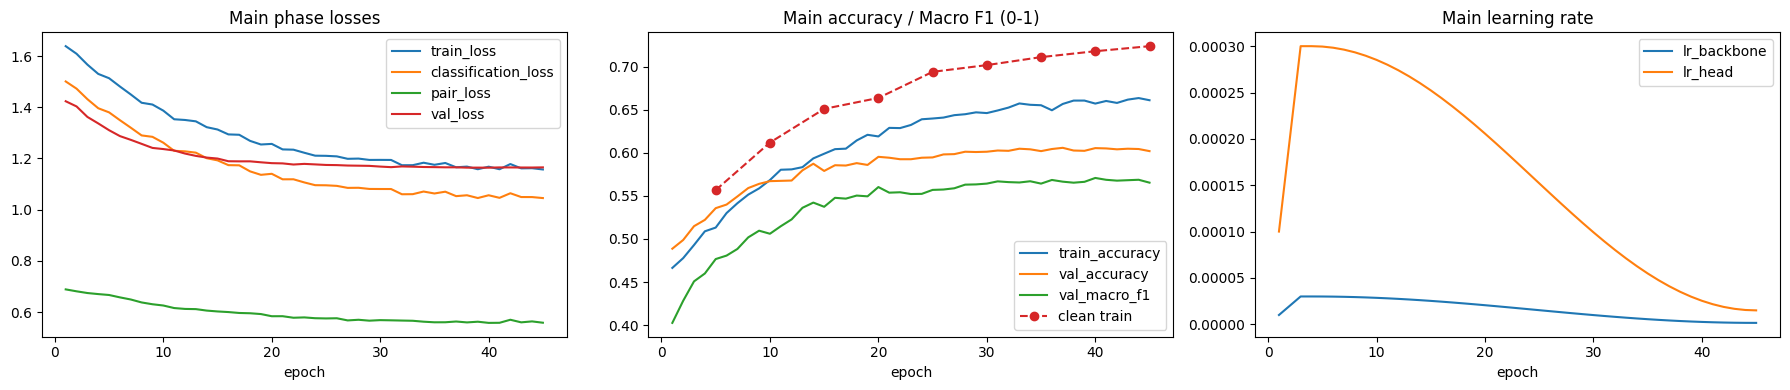

Evaluate:   0%|          | 0/45 [00:00<?, ?it/s]

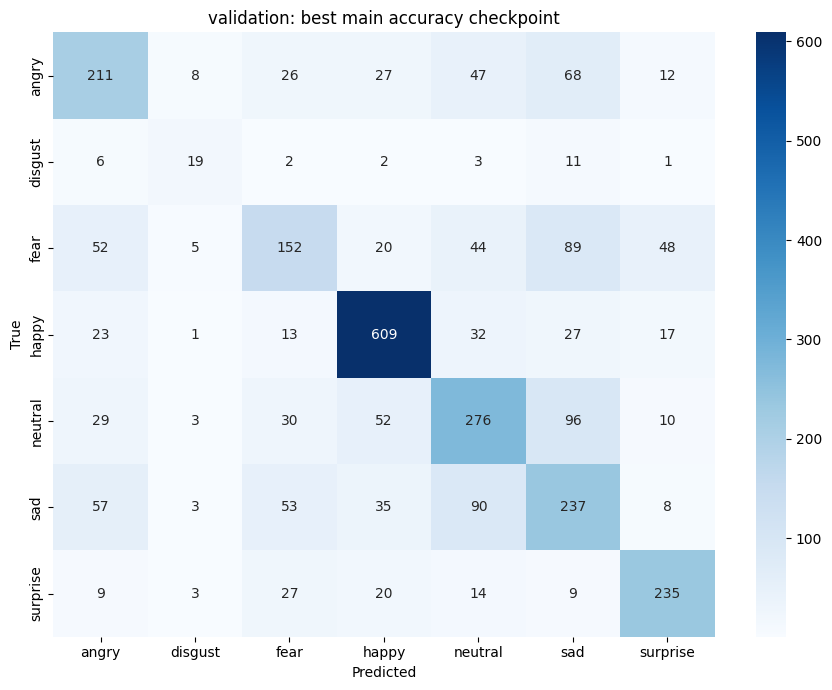

validation {
  "loss": 1.1654926593691495,
  "accuracy": 0.6057122953674677,
  "macro_f1": 0.5664478836466781,
  "balanced_accuracy": 0.5661888589763969,
  "global_accuracy": 0.6029258098223615,
  "changed_predictions": 180,
  "helpful_corrections": 64,
  "harmful_corrections": 56,
  "sample_count": 2871,
  "mean_gates": [
    0.014071173034608364,
    0.12295550107955933,
    0.09148991107940674
  ]
}
              precision    recall  f1-score   support

       angry     0.5452    0.5288    0.5369       399
     disgust     0.4524    0.4318    0.4419        44
        fear     0.5017    0.3707    0.4264       410
       happy     0.7961    0.8435    0.8191       722
     neutral     0.5455    0.5565    0.5509       496
         sad     0.4413    0.4907    0.4647       483
    surprise     0.7100    0.7413    0.7253       317

    accuracy                         0.6057      2871
   macro avg     0.5703    0.5662    0.5664      2871
weighted avg     0.6014    0.6057    0.6017      287

In [14]:
fig, axes = plt.subplots(1,3,figsize=(18,4))
history.plot(x='epoch', y=['train_loss','classification_loss','pair_loss','val_loss'], ax=axes[0], title='Main phase losses')
history.plot(x='epoch', y=['train_accuracy','val_accuracy','val_macro_f1'], ax=axes[1], title='Main accuracy / Macro F1 (0-1)')
clean = history.dropna(subset=['clean_train_accuracy'])
axes[1].plot(clean.epoch, clean.clean_train_accuracy, 'o--', label='clean train')
axes[1].legend()
history.plot(x='epoch', y=['lr_backbone','lr_head'], ax=axes[2], title='Main learning rate')
fig.tight_layout()
fig.savefig(RUN_DIR/'training_history.png', dpi=150)
plt.show()
validation_result = evaluate(model, loaders['val'], DEVICE, CFG)
validation_paths = split_manifest.loc[split_manifest['split']=='val','path'].tolist()
validation_metrics = export_report(validation_result, RUN_DIR, 'validation', PAIRS, validation_paths)

## 8. Test cuối — sau khi chốt cấu hình

Đặt `RUN_FINAL_TEST=False` trong lúc chọn preset bằng validation. Sau khi chốt,
bật True để Run All xuất report test. Cell nạp cấu hình và danh sách cặp từ run
đã lưu, không chọn cặp hay class weights dựa trên test.

Dataset này thường có 7.178 ảnh test; không so trực tiếp với benchmark dùng
riêng PrivateTest 3.589 ảnh. Test cũng đã được tham khảo trong quá trình phát
triển dự án, nên cần báo cáo điều này thay vì xem là bộ kiểm tra chưa từng dùng.

In [ ]:
def evaluate_final_test(run_dir, root, device):
    metadata = json.loads((Path(run_dir)/'training.json').read_text(encoding='utf-8'))
    cfg = metadata['config']
    restored = load_trained_model(Path(run_dir)/metadata['checkpoint_file'], device)
    restored = prepare_model(restored, cfg, device)
    dataset = datasets.ImageFolder(Path(root)/'test', transform=build_transforms(cfg))
    check_classes(dataset)
    attach_image_cache(cfg, dataset)
    loader = DataLoader(dataset, batch_size=cfg['batch_size'], shuffle=False,
                        num_workers=cfg['num_workers'], pin_memory=device.type=='cuda', worker_init_fn=seed_worker)
    result = evaluate(restored, loader, device, cfg)
    paths = [str(Path(p).relative_to(root)) for p,_ in dataset.samples]
    metrics = export_report(result, run_dir, 'test', metadata['model_config']['pairs'], paths)
    print(f'Test accuracy: {result["accuracy"]:.2%} | Test Macro F1: {result["macro_f1"]:.2%}')
    return result, metrics


RUN_FINAL_TEST = True
if RUN_FINAL_TEST:
    test_result, test_metrics = evaluate_final_test(RUN_DIR, DATA_ROOT, DEVICE)
else:
    print('Chưa đọc test; tiếp tục chọn cấu hình bằng validation.')

## 9. File nào cần tải?

Thư mục run hiện tại được in bởi `Output:`. Mỗi lần chạy cell tạo dữ liệu tạo
một thư mục mới, không tự resume. Các file quan trọng:

- **`pair_correction_best_checkpoint.pth`**: nên tải; weights + kiến trúc,
  cặp, nhãn, tiền xử lý và best main epoch. Nạp được trên một GPU hoặc CPU.
- `pair_correction_best.pth`: raw state dict; phải có cùng kiến trúc/cặp.
- `pilot_global_best_checkpoint.pth`, `pilot_history.csv`: chi phí và kết quả pilot.
- `pairs.json`, `pilot_pair_ranking.csv`: cặp được chọn và nguồn chọn cặp.
- `training.json`, `model_config.json`, `class_weights.csv`, `split_manifest.csv`.
- `main_history.csv`, report, confusion matrix, predictions, pair diagnostics.

Sau khi chạy cell định nghĩa model:

```python
restored = load_trained_model(RUN_DIR/'pair_correction_best_checkpoint.pth', DEVICE)
with torch.inference_mode():
    logits = restored(tensor)['logits']  # tensor B×3×112×112, đã chuẩn hóa
```

Không dùng weights này trực tiếp với ứng dụng CCT/CNN cũ. Checkpoint không
lưu optimizer để resume train và không đại diện weights của batch đang chạy.
Kết quả chỉ là best main validation checkpoint; best pilot được lưu riêng.

**Cách đối chứng:** chạy `global_ce`, `pair_ce`, `global_balanced`, `pair_balanced`
cùng split/pilot/seed và ngân sách. Nếu nhánh có lợi, so thêm `pair_no_gate`
và `pair_random`. Thử nhiều seed train, giữ mining_seed/split_seed để giữ
cùng pilot/cặp/split. Pretraining ImageNet có thể giúp hoặc không; so random
initialization trong thí nghiệm riêng nếu cần xác định đóng góp pretrain.

Nguồn thành phần: [MobileNetV3](https://arxiv.org/abs/1905.02244),
[Class-Balanced Loss](https://arxiv.org/abs/1901.05555).
Các ý tưởng specialist/pairwise có tiền lệ; notebook không xác nhận tính mới
học thuật hoặc bảo đảm accuracy. Báo cáo cả chi phí pilot, inference latency
đo thực tế và Macro F1, không chỉ số tham số.